# Chapter 87: Human Capital, Technology, Signaling, and Discrimination

This notebook reruns four worked examples from the chapter: the skill premium after a biased technology shock, a training decision decided by the horizon, automation with scale and new tasks, and shrinkage toward a group mean. Every number is one of the chapter's hypothetical values; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def relative_wage_ces(A_ratio, HL, sigma=2.0):
    """skill-biased-technical-change (chapter 87): ln(H/L) = ln(A_H/A_L) - sigma ln(w_H/w_L),
    so w_H/w_L = (A_ratio / HL)^(1/sigma). Book (sigma 2): A 1, H/L 0.25 gives 2; A 2 gives 2.83;
    H/L 0.40 gives 2.24.
    """
    return (A_ratio / HL) ** (1.0 / sigma)


def annuity_factor(r, n):
    """Present value of 1 per period for n periods: (1 - (1 + r)^-n) / r (n when r = 0)."""
    return float(n) if r == 0 else (1.0 - (1.0 + r) ** (-n)) / r


def annuity_pv(payment, r, n):
    """payment x annuity_factor(r, n)."""
    return payment * annuity_factor(r, n)


def task_employment(labor_tasks, new_tasks, scale, per_worker):
    """task-displacement-and-reinstatement (chapter 87): employment = (labor_tasks + new_tasks) x scale / per_worker.

    Book (per worker 7): 50/7 = 7.14; 50(1.2)/7 = 8.57; (50+15)(1.2)/7 = 78/7 = 11.14; 65/7 = 9.29;
    100/7 = 14.29; 80(1.2)/7 = 13.71. Implemented by Part 10 (chapter 87 is its only user).
    """
    activities = (labor_tasks + new_tasks) * scale
    return {"activities": activities, "employment": activities / per_worker}


def shrinkage_posterior(lam, s, mu):
    """statistical-discrimination (chapter 87): E(theta | s, g) = lam s + (1 - lam) mu.

    Book (mu 60): 0.75(80) + 0.25(60) = 75; 0.25(80) + 0.75(60) = 65; at s 50: 52.5 and 57.5;
    lam 0.90: 78. Implemented by Part 10 (chapter 87 is its only user).
    """
    return lam * s + (1 - lam) * mu


plt.rcParams.update(HOUSE_RC)


labor = SimpleNamespace(relative_wage_ces=relative_wage_ces)


choice = SimpleNamespace(annuity_factor=annuity_factor, annuity_pv=annuity_pv)


production = SimpleNamespace(task_employment=task_employment)


information = SimpleNamespace(shrinkage_posterior=shrinkage_posterior)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'skill-biased-technical-change': {'A0': 1,
                                   'A1': 2,
                                   'HL': 0.25,
                                   'HL2': 0.4,
                                   'ratio0': 2,
                                   'ratio1': 2.83,
                                   'ratio2': 2.24,
                                   'rise_pct': 41},
 'ben-porath-life-cycle-human-capital-model': {'gain': 3000,
                                               'r': 0.05,
                                               'cost': 20000,
                                               'cost_sub': 15000,
                                               'pv20_printed_as': 37386,
                                               'pv20_exact_2dp': 37386.63,
                                               'npv20_printed_as': 17386,
                                               'pv5': 12988,
                                               'pv8': 19390},
 'task-displacement-and-reinstatement': {'per_worker': 7,
                                         'baseline': 10,
                                         'labor_after': 50,
                                         'e_after': 7.14,
                                         'displaced': 2.86,
                                         'scale': 1.2,
                                         'e_scale': 8.57,
                                         'new': 15,
                                         'activities': 78,
                                         'e_full': 11.14,
                                         'e_new_only': 9.29,
                                         'e_double': 14.29,
                                         'e_new30': 13.71},
 'statistical-discrimination': {'mu': 60,
                                'cutoff': 70,
                                'lamA': 0.75,
                                'lamB': 0.25,
                                's': 80,
                                'postA': 75,
                                'postB': 65,
                                's_low': 50,
                                'postA_low': 52.5,
                                'postB_low': 57.5,
                                'lam_high': 0.9,
                                'post_high': 78},
 'constructed': {'skill-biased-technical-change': {'A': [3], 'HL': [0.55]},
                 'statistical-discrimination': {'lamB': [0.5], 's': [90]}}}


def premium_picture(tech=2, hl=0.25):
    w = labor.relative_wage_ces(tech, hl, 2.0)
    base = labor.relative_wage_ces(1, 0.25, 2.0)
    change = w / base - 1
    ws = np.linspace(1.0, 4.2, 200)
    fig, ax = new_figure()
    if tech != 1:
        ax.plot(ws, 1 / ws ** 2, color=PALETTE["grey"], linewidth=1.4, linestyle="dashed")
        label(ax, 1.05, 1 / 1.05 ** 2, "neutral A = 1", col="grey", dx=6, dy=-4, va="top")
    ax.plot(ws, tech / ws ** 2, color=PALETTE["teal"], linewidth=2.2)
    hline(ax, hl, f"supply H/L = {num(hl)}", col="navy", style="solid", x_frac=0.62)
    lx = math.sqrt(tech / 0.75)
    label(ax, lx, tech / lx ** 2, f"demand, A_H/A_L = {num(tech, 0)}", col="teal", dx=6, dy=4)
    mark(ax, w, hl, f"w_H/w_L = {num(w)}", col="terracotta", dx=6, dy=-8, va="top")
    ax.set_xlim(1.0, 4.2)
    ax.set_ylim(0, 1.25)
    ax.set_xlabel("Relative wage w_H / w_L")
    ax.set_ylabel("Relative skill H / L")
    metrics = {"Relative wage w_H/w_L": num(w), "Change vs starting premium 2": plus(100 * change, 1) + "%"}
    steps = [f"ln({num(hl)}) = ln({num(tech, 0)}) - 2 ln(w_H/w_L)",
             f"w_H/w_L = ({num(tech, 0)} / {num(hl)})^(1/2) = {num(tech / hl, 4)}^(1/2) = {num(w, 4)}",
             f"Change: {num(w, 4)} / 2 - 1 = {num(change, 4)}, or {plus(100 * change, 1)}%"]
    interp = (f"Hypothetical market-clearing schedule from the chapter. With technology ratio {num(tech, 0)} and skill "
              f"supply {num(hl)}, the premium is ({num(tech, 0)} / {num(hl)})^(1/2) = {num(w)}, "
              f"{plus(100 * change, 1)}% against the starting premium of 2. Biased technology raises the premium; "
              f"added skill supply lowers it.")
    alt = (f"Downward relative-demand curve for A_H/A_L = {num(tech, 0)} and a dashed neutral curve, cut by supply at "
           f"H/L = {num(hl)}; the premium is {num(w)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def training_picture(t=20, cost=20000):
    b = BV["ben-porath-life-cycle-human-capital-model"]
    gain, r = b["gain"], b["r"]
    pv = choice.annuity_pv(gain, r, t)
    npv = pv - cost
    years = np.arange(1, t + 1)
    cum = [choice.annuity_pv(gain, r, k) for k in years]
    fig, ax = new_figure()
    ax.bar(years, cum, color=PALETTE["teal"], width=0.7)
    hline(ax, cost, f"cost {num(cost, 0)}", col="terracotta", style="solid", x_frac=0.62)
    label(ax, t, pv, num(pv, 0), dx=0, dy=4, ha="center", box=False)
    ax.set_xlim(0, 21)
    ax.set_xticks([1, 5, 8, 10, 15, 20])
    ax.set_ylim(0, 44000)
    ax.set_xlabel("Post-training years counted")
    ax.set_ylabel("Present value of gains")
    verdict = "worthwhile" if npv > 0 else ("break-even (a tie)" if npv == 0 else "not worthwhile")
    factor = (1 - (1 + r) ** (-t)) / r
    metrics = {"PV of benefit": num(pv, 0), "Total cost": num(cost, 0), "NPV": num(npv, 0),
               "Verdict": verdict.capitalize()}
    steps = [f"Annuity factor = (1 - 1.05^-{t}) / 0.05 = {num(factor, 4)}",
             f"PV = 3,000 x {num(factor, 4)} = {num(pv, 0)}",
             f"NPV = {num(pv, 0)} - {num(cost, 0)} = {num(npv, 0)}, so the program is {verdict}"]
    interp = (f"Hypothetical program from the chapter. A 3,000 annual gain over {t} years at 5 percent is worth "
              f"3,000 x {num(factor, 4)} = {num(pv, 0)} at the end of training, against a cost of {num(cost, 0)}: NPV "
              f"{num(npv, 0)}, so the program is {verdict}. The horizon, not the training itself, decides.")
    alt = (f"Bars of cumulative present value over {t} years, reaching {num(pv, 0)}, against a cost line at "
           f"{num(cost, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def tasks_picture(scale=1.2, newt=15):
    b = BV["task-displacement-and-reinstatement"]
    pw, base = b["per_worker"], b["baseline"]
    after = production.task_employment(50, 0, 1.0, pw)["employment"]
    scaled = production.task_employment(50, 0, scale, pw)["employment"]
    final = production.task_employment(50, newt, scale, pw)
    fin = final["employment"]
    disp, sc, rein = after - base, scaled - after, fin - scaled
    fig, ax = new_figure()
    names = ["Baseline", "Displacement", "Scale", "Reinstatement", "Final"]
    bottoms = [0, after, min(after, scaled), scaled, 0]
    heights = [base, -disp, abs(sc), rein, fin]
    cols = ["grey", "terracotta", "gold", "teal", "navy"]
    xs = np.arange(5)
    ax.bar(xs, heights, bottom=bottoms, color=[PALETTE[c] for c in cols], width=0.6)
    vals = [num(base), plus(disp), plus(sc), plus(rein), num(fin)]
    tops = [base, base, max(after, scaled), scaled + rein, fin]
    for x, tp, v in zip(xs, tops, vals):
        label(ax, x, tp, v, dx=0, dy=4, ha="center", box=False)
    ax.set_xticks(xs, names)
    ax.set_ylim(0, 27)
    ax.set_xlabel("Step")
    ax.set_ylabel("Workers")
    share = 50 / 100
    metrics = {"Employment after automation": num(after), "Scale effect": plus(sc), "Reinstatement effect": plus(rein),
               "Final employment": num(fin), "Change vs baseline 10": plus(fin - base)}
    steps = [f"Displacement: 50 / 7 = {num(after)}, a change of {plus(disp)}",
             f"Scale: 50 x {num(scale, 1)} / 7 = {num(scaled)}, adding {plus(sc)}",
             f"Reinstatement: (50 + {newt}) x {num(scale, 1)} = {num(final['activities'], 1)} activities; "
             f"{num(final['activities'], 1)} / 7 = {num(fin)}",
             f"Net change: {num(fin)} - 10 = {plus(fin - base)}"]
    interp = (f"Hypothetical plant from the chapter. Automation cuts labor tasks from 70 to 50 (50 / 7 = {num(after)} "
              f"workers). Output scale {num(scale, 1)} and {newt} new tasks give (50 + {newt}) x {num(scale, 1)} / 7 = "
              f"{num(fin)} workers, {plus(fin - base)} against the baseline of 10. Labor's share of the original "
              f"tasks is {pct(share, 0)} after automation in every case.")
    alt = (f"Waterfall from 10 workers: displacement {plus(disp)}, scale {plus(sc)}, reinstatement {plus(rein)}, ending "
           f"at {num(fin)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def shrinkage_picture(lamb=0.25, s=80):
    b = BV["statistical-discrimination"]
    mu, cut, lamA = b["mu"], b["cutoff"], b["lamA"]
    pa = information.shrinkage_posterior(lamA, s, mu)
    pb = information.shrinkage_posterior(lamb, s, mu)
    fig, ax = new_figure()
    ax.axhline(0, color=PALETTE["grey"], linewidth=1.2)
    vline(ax, mu, "prior 60", col="grey", y_frac=0.95)
    vline(ax, cut, "cutoff 70", col="terracotta", style="solid", y_frac=0.80)
    mark(ax, s, 0, f"score {num(s, 0)}", col="ink", dx=0, dy=8, ha="center")
    mark(ax, pa, 0.5, f"A: {num(pa, 1)}", col="teal", dx=0, dy=8, ha="center")
    mark(ax, pb, -0.5, f"B: {num(pb, 1)}", col="gold", dx=0, dy=-8, ha="center", va="top")
    ax.set_xlim(40, 100)
    ax.set_ylim(-1.2, 1.4)
    ax.set_yticks([0.5, 0, -0.5], ["Group A", "Score", "Group B"])
    ax.set_xlabel("Predicted productivity")
    ax.set_ylabel("Applicant")
    ha, hb = pa >= cut, pb >= cut
    def yes(h, p=None):
        if h and p is not None and abs(p - cut) < 1e-9:
            return "hired (exactly at the cutoff, a tie)"
        return "hired" if h else "not hired"
    metrics = {"Posterior A": num(pa, 1), "Posterior B": num(pb, 1), "Hire A": "Yes" if ha else "No",
               "Hire B": "Yes" if hb else "No"}
    steps = [f"A: 0.75 x {num(s, 0)} + 0.25 x 60 = {num(0.75 * s, 2)} + 15 = {num(pa, 1)}",
             f"B: {num(lamb)} x {num(s, 0)} + {num(1 - lamb)} x 60 = {num(lamb * s, 2)} + {num((1 - lamb) * 60, 2)} = "
             f"{num(pb, 1)}",
             f"Cutoff 70: A is {yes(ha, pa)}, B is {yes(hb, pb)}"]
    if abs(pa - pb) < 1e-9:
        cmp = "the two forecasts are equal"
    else:
        hi, lo = ("A", "B") if pa > pb else ("B", "A")
        heavier = "A" if lamA < lamb else "B"
        if s < mu:
            why = f"a score below the mean of 60 is pulled up more for {heavier}, whose score gets less weight"
        else:
            why = f"a score above the mean of 60 is pulled down more for {heavier}, whose score gets less weight"
        cmp = f"{hi}'s forecast is higher, because {why}"
    interp = (f"Hypothetical hiring exercise from the chapter. With score {num(s, 0)}, A's forecast is 0.75 x "
              f"{num(s, 0)} + 0.25 x 60 = {num(pa, 1)} and B's is {num(lamb)} x {num(s, 0)} + {num(1 - lamb)} x 60 = "
              f"{num(pb, 1)}; {cmp}. Against the cutoff of 70, A is {yes(ha, pa)} and B is {yes(hb, pb)}.")
    alt = (f"Number line from 40 to 100 with the prior at 60, the cutoff at 70, the score {num(s, 0)}, and forecasts "
           f"{num(pa, 1)} for A and {num(pb, 1)} for B.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Skill-biased technical change: the premium after a technology shock

Hypothetical schedule with elasticity 2.

$$\ln(H/L)=\ln(A_H/A_L)-2\ln(w_H/w_L), \qquad \ln(0.25)=\ln(2)-2\ln(w_H/w_L)$$

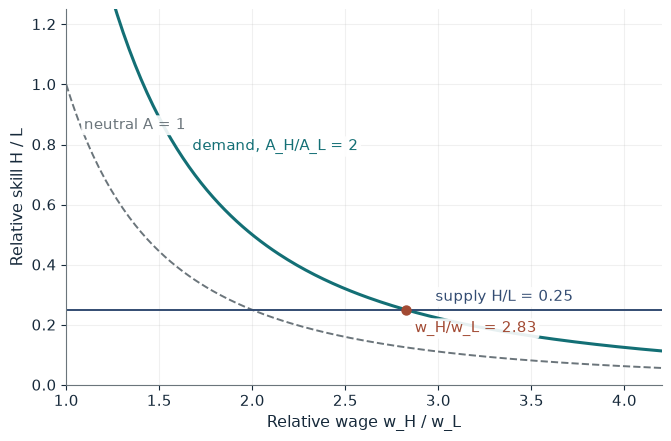

Relative wage w_H/w_L         2.83
Change vs starting premium 2  +41.4%

Worked steps:
  1. ln(0.25) = ln(2) - 2 ln(w_H/w_L)
  2. w_H/w_L = (2 / 0.25)^(1/2) = 8.0000^(1/2) = 2.8284
  3. Change: 2.8284 / 2 - 1 = 0.4142, or +41.4%

Hypothetical market-clearing schedule from the chapter. With technology ratio 2 and skill supply 0.25, the premium is (2 / 0.25)^(1/2) = 2.83, +41.4% against the starting premium of 2. Biased technology raises the premium; added skill supply lowers it.


In [2]:
show(premium_picture(tech=2, hl=0.25))

Change one input, `hl`, and hold the others at the book's values:

In [3]:
sweep(premium_picture, 'hl', [0.25, 0.4, 0.55], {'tech': 2}, ['Relative wage w_H/w_L'])

hl | Relative wage w_H/w_L
0.25 | 2.83
0.4 | 2.24
0.55 | 1.91


Doubling the technology ratio lifts the premium from 2 to 2.83; supply of 0.40 brings it to 2.24.

## 2. Ben-Porath: is training worth it?

Hypothetical program: 3,000 a year more, 5 percent, cost 20,000.

$$3{,}000\frac{1-(1.05)^{-20}}{0.05}\approx37{,}386$$

The exact value is 37,386.63, which the code rounds to 37,387.

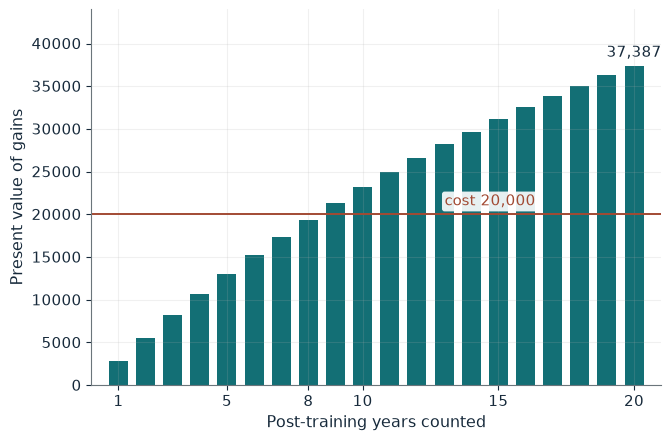

PV of benefit  37,387
Total cost     20,000
NPV            17,387
Verdict        Worthwhile

Worked steps:
  1. Annuity factor = (1 - 1.05^-20) / 0.05 = 12.4622
  2. PV = 3,000 x 12.4622 = 37,387
  3. NPV = 37,387 - 20,000 = 17,387, so the program is worthwhile

Hypothetical program from the chapter. A 3,000 annual gain over 20 years at 5 percent is worth 3,000 x 12.4622 = 37,387 at the end of training, against a cost of 20,000: NPV 17,387, so the program is worthwhile. The horizon, not the training itself, decides.


In [4]:
show(training_picture(t=20, cost=20000))

Change one input, `t`, and hold the others at the book's values:

In [5]:
sweep(training_picture, 't', [5, 8, 20], {'cost': 20000}, ['PV of benefit', 'NPV'])

t | PV of benefit | NPV
5 | 12,988 | -7,012
8 | 19,390 | -610
20 | 37,387 | 17,387


Twenty years make the program worthwhile; five or eight years do not at the full cost.

## 3. Task displacement and reinstatement: automation, scale, and new tasks

Hypothetical plant: labor tasks fall from 70 to 50, 7 per worker.

$$\frac{50}{7}\approx7.14, \qquad (50+15)(1.2)=78$$

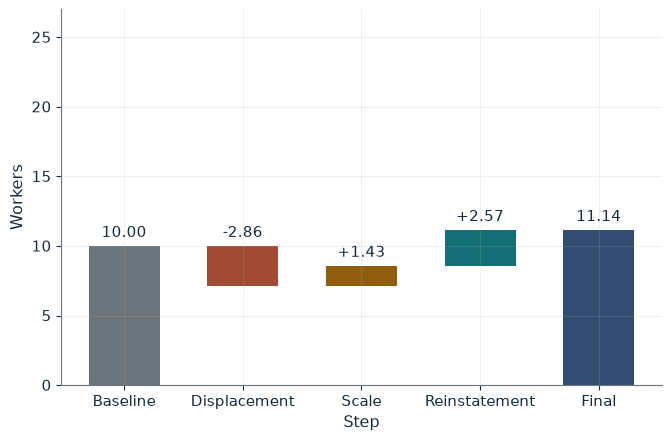

Employment after automation  7.14
Scale effect                 +1.43
Reinstatement effect         +2.57
Final employment             11.14
Change vs baseline 10        +1.14

Worked steps:
  1. Displacement: 50 / 7 = 7.14, a change of -2.86
  2. Scale: 50 x 1.2 / 7 = 8.57, adding +1.43
  3. Reinstatement: (50 + 15) x 1.2 = 78.0 activities; 78.0 / 7 = 11.14
  4. Net change: 11.14 - 10 = +1.14

Hypothetical plant from the chapter. Automation cuts labor tasks from 70 to 50 (50 / 7 = 7.14 workers). Output scale 1.2 and 15 new tasks give (50 + 15) x 1.2 / 7 = 11.14 workers, +1.14 against the baseline of 10. Labor's share of the original tasks is 50% after automation in every case.


In [6]:
show(tasks_picture(scale=1.2, newt=15))

Change one input, `newt`, and hold the others at the book's values:

In [7]:
sweep(tasks_picture, 'newt', [0, 15, 30], {'scale': 1.2}, ['Final employment'])

newt | Final employment
0 | 8.57
15 | 11.14
30 | 13.71


Scale alone restores 8.57 workers; 15 new tasks bring employment to 11.14, above the baseline of 10.

## 4. Statistical discrimination: shrinkage and unequal reliability

Hypothetical hiring: prior 60, cutoff 70, weight 0.75 for A.

$$E(\theta_i\mid s_i,g)=\lambda_gs_i+(1-\lambda_g)\mu_g, \qquad E(\theta\mid80,A)=0.75(80)+0.25(60)=75$$

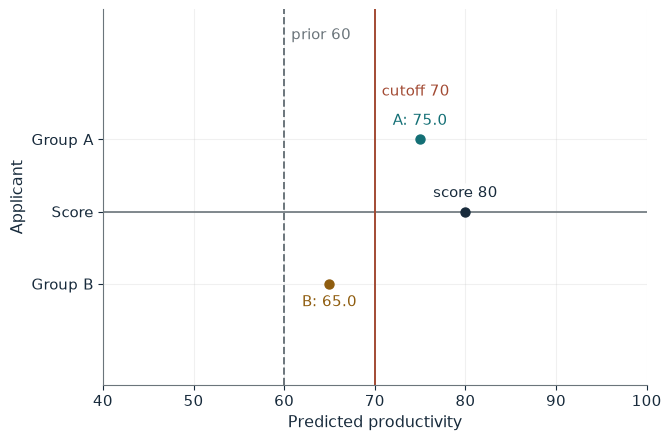

Posterior A  75.0
Posterior B  65.0
Hire A       Yes
Hire B       No

Worked steps:
  1. A: 0.75 x 80 + 0.25 x 60 = 60.00 + 15 = 75.0
  2. B: 0.25 x 80 + 0.75 x 60 = 20.00 + 45.00 = 65.0
  3. Cutoff 70: A is hired, B is not hired

Hypothetical hiring exercise from the chapter. With score 80, A's forecast is 0.75 x 80 + 0.25 x 60 = 75.0 and B's is 0.25 x 80 + 0.75 x 60 = 65.0; A's forecast is higher, because a score above the mean of 60 is pulled down more for B, whose score gets less weight. Against the cutoff of 70, A is hired and B is not hired.


In [8]:
show(shrinkage_picture(lamb=0.25, s=80))

Change one input, `lamb`, and hold the others at the book's values:

In [9]:
sweep(shrinkage_picture, 'lamb', [0.25, 0.5, 0.75, 0.9], {'s': 80}, ['Posterior B', 'Hire B'])

lamb | Posterior B | Hire B
0.25 | 65.0 | No
0.5 | 70.0 | Yes
0.75 | 75.0 | Yes
0.9 | 78.0 | Yes


The same score of 80 gives A 75 and B 65; equal reliability removes the gap.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

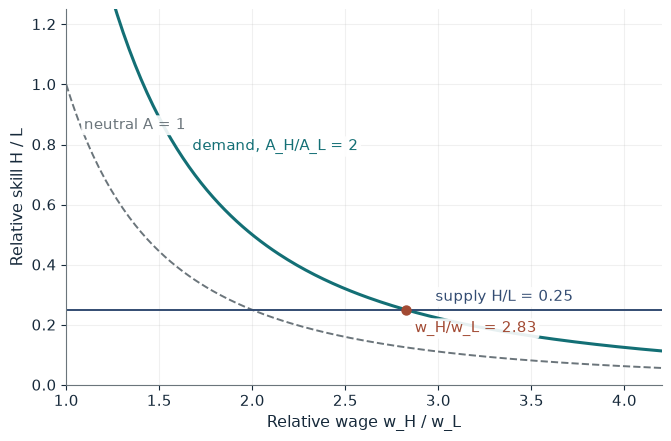

Relative wage w_H/w_L         2.83
Change vs starting premium 2  +41.4%

Worked steps:
  1. ln(0.25) = ln(2) - 2 ln(w_H/w_L)
  2. w_H/w_L = (2 / 0.25)^(1/2) = 8.0000^(1/2) = 2.8284
  3. Change: 2.8284 / 2 - 1 = 0.4142, or +41.4%

Hypothetical market-clearing schedule from the chapter. With technology ratio 2 and skill supply 0.25, the premium is (2 / 0.25)^(1/2) = 2.83, +41.4% against the starting premium of 2. Biased technology raises the premium; added skill supply lowers it.


In [10]:
show(premium_picture(tech=2, hl=0.25))

## Practice

**1.** With A_H/A_L = 3 and H/L = 0.55, what is the premium?

<details><summary>Answer</summary>

(3 / 0.55)^(1/2) = 2.34.

</details>

**2.** With eight years and a cost of 15,000, is training worthwhile?

<details><summary>Answer</summary>

PV 19,390 > 15,000, NPV 4,390, so yes.

</details>

**3.** With lambda_B = 0.50 and a score of 90, is B hired?

<details><summary>Answer</summary>

0.5 x 90 + 0.5 x 60 = 75 >= 70, so yes.

</details>